In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Con $\tau = \lVert R\,t \rVert_\infty$, la sensibilidad de la duración del proyecto a cada actividad es el gradiente $\partial\tau/\partial t_i$. Considere el proyecto cuyo cuadro se adjunta, que tiene más de una ruta crítica.

In [4]:
pregunta_1 = "1. Construya R, calcule R·t y determine las rutas críticas.  "
pregunta_2 = "2. Calcule ∂τ/∂t_i para cada actividad como la media de los vectores indicadores de las rutas críticas (lo que da `tau_sensitivity`). ¿Qué valores aparecen y qué significan 1, 0 y los intermedios?  "
pregunta_3 = "3. Compruebe por diferencias finitas, para una actividad de cada clase, qué ocurre con τ al aumentar y al disminuir su duración en un día. ¿Por qué la derivada «no existe» en las actividades intermedias?  "
pregunta_4 = "4. Demuestre que la suma de las sensibilidades es la longitud (en número de actividades) media de las rutas críticas y compruébelo.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Construya R, calcule R·t y determine las rutas críticas.  

2. Calcule ∂τ/∂t_i para cada actividad como la media de los vectores indicadores de las rutas críticas (lo que da `tau_sensitivity`). ¿Qué valores aparecen y qué significan 1, 0 y los intermedios?  

3. Compruebe por diferencias finitas, para una actividad de cada clase, qué ocurre con τ al aumentar y al disminuir su duración en un día. ¿Por qué la derivada «no existe» en las actividades intermedias?  

4. Demuestre que la suma de las sensibilidades es la longitud (en número de actividades) media de las rutas críticas y compruébelo.  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 2       ),
    ('B'     , '---'      , 3       ),
    ('C'     , '---'      , 3       ),
    ('D'     , 'B,C'      , 2       ),
    ('E'     , 'A,B,C'    , 1       ),
    ('F'     , 'D'        , 5       ),
    ('G'     , 'F'        , 8       ),
    ('H'     , 'E,G'      , 8       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,2
B,---,3
C,---,3
D,"B,C",2
E,"A,B,C",1
F,D,5
G,F,8
H,"E,G",8


El proyecto corresponde a la apertura de una clínica veterinaria; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Estudio de mercado y local',
    'B': 'Proyecto de reforma y licencia',
    'C': 'Obra de reforma',
    'D': 'Instalación de quirófano y radiología',
    'E': 'Mobiliario y equipamiento clínico',
    'F': 'Software de gestión',
    'G': 'Selección de personal',
    'H': 'Acuerdos con proveedores',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de mercado y local
B,Proyecto de reforma y licencia
C,Obra de reforma
D,Instalación de quirófano y radiología
E,Mobiliario y equipamiento clínico
F,Software de gestión
G,Selección de personal
H,Acuerdos con proveedores


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
R = proyecto.path_matrix(dummies=False)
t = datos_proyecto['duration'][R.columns]

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Construya R, calcule R·t y determine las rutas críticas.  

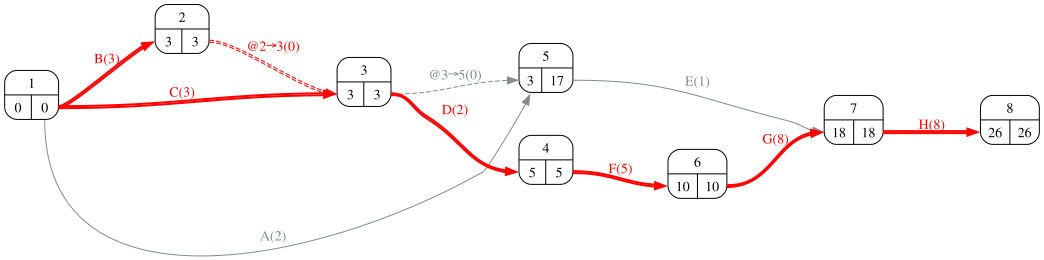

In [9]:
#| fig-cap: "Grafo PERT con tiempos y rutas críticas"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [10]:
Rt = R @ t
tau = float(Rt.max())
criticas = Rt.index[np.isclose(Rt, tau)].tolist()
display(pd.DataFrame({'actividades': [' - '.join(R.columns[R.loc[r] == 1]) for r in R.index], 'duración': Rt}))
Markdown(f'τ = {tau:.0f}; rutas críticas: {", ".join(criticas)}.')

,actividades,duración
Route_1,A - E - H,11
Route_2,B - D - F - G - H,26
Route_3,B - E - H,12
Route_4,C - D - F - G - H,26
Route_5,C - E - H,12


τ = 26; rutas críticas: Route_2, Route_4.

## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. Calcule ∂τ/∂t_i para cada actividad como la media de los vectores indicadores de las rutas críticas (lo que da `tau_sensitivity`). ¿Qué valores aparecen y qué significan 1, 0 y los intermedios?  

In [12]:
indicadores = R.loc[criticas]
gradiente = indicadores.mean()
display(indicadores)
pd.DataFrame({'∂τ/∂t (media de indicadores)': gradiente, 'tau_sensitivity': proyecto.tau_sensitivity(t.to_dict()).reindex(R.columns)}).T

,A,B,C,D,E,F,G,H
Route_2,0,1,0,1,0,1,1,1
Route_4,0,0,1,1,0,1,1,1


,A,B,C,D,E,F,G,H
∂τ/∂t (media de indicadores),0.0,0.5,0.5,1.0,0.0,1.0,1.0,1.0
tau_sensitivity,0.0,0.5,0.5,1.0,0.0,1.0,1.0,1.0


Valor 1: la actividad está en todas las rutas críticas (alargarla o acortarla cambia τ uno a uno). Valor 0: no está en ninguna (τ no cambia, al menos para cambios pequeños). Valor intermedio, por ejemplo 0,5: está en una de las dos rutas críticas; alargarla sí alarga el proyecto, pero acortarla no lo acorta, porque la otra ruta sigue midiendo lo mismo.

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. Compruebe por diferencias finitas, para una actividad de cada clase, qué ocurre con τ al aumentar y al disminuir su duración en un día. ¿Por qué la derivada «no existe» en las actividades intermedias?  

In [14]:
def tau_con(act, delta):
    t2 = t.copy(); t2[act] += delta
    return float((R @ t2).max())
clases = {v: gradiente.index[np.isclose(gradiente, v)].tolist() for v in sorted(gradiente.unique())}
filas = {}
for v, acts in clases.items():
    a = acts[0]
    filas[a] = {'∂τ/∂t': v, 'τ(t+1) − τ': tau_con(a, 1) - tau, 'τ(t−1) − τ': tau_con(a, -1) - tau}
pd.DataFrame(filas).T

,∂τ/∂t,τ(t+1) − τ,τ(t−1) − τ
A,0.0,0.0,0.0
B,0.5,1.0,0.0
D,1.0,1.0,-1.0


Para las actividades con valor intermedio la pendiente por la derecha (+1) y por la izquierda (0) son distintas: τ es un máximo de funciones lineales y en los puntos donde dos rutas empatan tiene una esquina. La media de los indicadores es un *subgradiente*, no una derivada: el valor que reparte la sensibilidad entre las rutas empatadas.

## Apartado 4

In [15]:
display(Markdown(pregunta_4))

4. Demuestre que la suma de las sensibilidades es la longitud (en número de actividades) media de las rutas críticas y compruébelo.  

In [16]:
suma = float(gradiente.sum())
longitud_media = float(indicadores.sum(axis=1).mean())
Markdown(f'''Σ_i ∂τ/∂t_i = Σ_i (1/k) Σ_{{r crítica}} R_ri = (1/k) Σ_r Σ_i R_ri = media del número de actividades de las rutas críticas. Aquí Σ = {suma:.2f} y la longitud media de las {len(criticas)} rutas críticas es {longitud_media:.2f}.''')

Σ_i ∂τ/∂t_i = Σ_i (1/k) Σ_{r crítica} R_ri = (1/k) Σ_r Σ_i R_ri = media del número de actividades de las rutas críticas. Aquí Σ = 5.00 y la longitud media de las 2 rutas críticas es 5.00.